In [1]:
import gensim
import random
import pandas as pd
import numpy as np
from keras import layers
from keras import models
from gensim.models import Word2Vec
from clean_text import clean_text
from nltk.tokenize import sent_tokenize
from nltk.tokenize import word_tokenize
from keras.preprocessing.text import Tokenizer
from sklearn.model_selection import train_test_split
from keras.preprocessing.sequence import pad_sequences

ImportError: cannot import name 'pad_sequences' from 'keras.preprocessing.sequence' (c:\Users\user\Anaconda3\lib\site-packages\keras\preprocessing\sequence.py)

In [ ]:
df = pd.read_csv("train.csv")
copy_df = df.copy()
copy_df.drop(["id", "discourse_id", "discourse_start", "discourse_end", "discourse_type_num", "predictionstring"], axis=1, inplace=True)

In [ ]:
copy_train_df = copy_df.copy()

In [ ]:
index = []
index.extend(random.choices(copy_train_df[copy_train_df.discourse_type=="Evidence"].index, k=40000))
index.extend(random.choices(copy_train_df[copy_train_df.discourse_type=="Claim"].index, k=40000))
print(len(index))

80000


In [ ]:
copy_train_df.drop(index, axis=0, inplace=True)

In [31]:
copy_train_df.discourse_type.value_counts()

Claim                   22656
Evidence                18964
Position                15419
Concluding Statement    13505
Lead                     9305
Counterclaim             5817
Rebuttal                 4337
Name: discourse_type, dtype: int64

In [35]:
copy_train_df.reset_index(drop=True, inplace=True)

In [36]:
discourse_text = []
discourse_type = []
for i,paragraph in enumerate(copy_train_df.discourse_text):
    types = []
    phrases = sent_tokenize(paragraph)
    types.append(copy_train_df.discourse_type[i])
    discourse_text.extend(phrases)
    discourse_type.extend(types*len(phrases))

In [38]:
copy_train_df = pd.DataFrame({"discourse_text":discourse_text, "discourse_type":discourse_type})

In [39]:
copy_train_df.discourse_type.value_counts()

Evidence                71574
Concluding Statement    42204
Lead                    28462
Claim                   25062
Position                18220
Counterclaim             7530
Rebuttal                 6619
Name: discourse_type, dtype: int64

In [40]:
copy_train_df.discourse_text = copy_train_df.discourse_text.apply(clean_text)

In [46]:
copy_df.discourse_text = copy_df.discourse_text.apply(clean_text)

In [48]:
corpus = copy_df.discourse_text.apply(lambda x: [word for word in word_tokenize(x)])

In [50]:
tk = Tokenizer()
tk.fit_on_texts(copy_df.discourse_text)

In [51]:
# Word2Vec Parameters 
dimension = 150
window = 8
# max_length = max([len(doc) for doc in corpus])
max_length = 50
vocab_size = len(list(tk.word_index.items()))

In [52]:
modele = Word2Vec(corpus, vector_size=dimension, window=window)
words = modele.wv

In [53]:
embedding = np.zeros((vocab_size+1, dimension))
for word,idx in tk.word_index.items():
    try:
        embedding[idx] =  words[word]
    except:
        pass

In [54]:
X_train, X_test, y_train, y_test = train_test_split(copy_train_df.discourse_text, copy_train_df.discourse_type, test_size=0.2, random_state=123)

In [55]:
seqTrain = tk.texts_to_sequences(X_train)
padTrain = pad_sequences(seqTrain, maxlen=max_length, padding='post')

In [56]:
def attention_layer(inputs, neurons):
    x = layers.Permute((2,1))(inputs)
    x = layers.Dense(neurons, activation="softmax")(x)
    x = layers.Permute((2,1), name="attention")(x)
    x = layers.multiply([inputs, x])
    return x

In [65]:
max_length=50

In [66]:
x_in = layers.Input(shape=(max_length,))

x = layers.Embedding(input_dim=embedding.shape[0],  
                     output_dim=embedding.shape[1], 
                     weights=[embedding],
                     input_length=max_length, trainable=False)(x_in)

x = attention_layer(x, neurons=max_length)
x = layers.Bidirectional(layers.LSTM(units=max_length, dropout=0.2, return_sequences=True ))(x)
x = layers.Bidirectional(layers.LSTM(units=max_length, dropout=0.2))(x)
x = layers.Dense(64, activation='relu')(x)
y_out = layers.Dense(7, activation='softmax')(x)

model = models.Model(x_in, y_out)
model.compile(loss='sparse_categorical_crossentropy',
              optimizer='adam', metrics=['accuracy'])

model.summary()

Model: "model_3"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_4 (InputLayer)           [(None, 50)]         0           []                               
                                                                                                  
 embedding_3 (Embedding)        (None, 50, 150)      7346550     ['input_4[0][0]']                
                                                                                                  
 permute_2 (Permute)            (None, 150, 50)      0           ['embedding_3[0][0]']            
                                                                                                  
 dense_8 (Dense)                (None, 150, 50)      2550        ['permute_2[0][0]']              
                                                                                            

In [60]:
dic_y_mapping = {n:label for n,label in 
                 enumerate(np.unique(y_train))}
inverse_dic = {v:k for k,v in dic_y_mapping.items()}
y_train = np.array([inverse_dic[y] for y in y_train])

In [67]:
training = model.fit(x=padTrain, y=y_train, batch_size=256, 
                     epochs=10, shuffle=True, verbose=1, 
                     validation_split=0.3)

Epoch 1/10
Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`) and attach the full output.
Cause: 'arguments' object has no attribute 'posonlyargs'
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert
Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`) and attach the full output.
Cause: 'arguments' object has no attribute 'posonlyargs'
To silence this warning, decorate the function with @tf.autograph.experimental.do_not_convert
437/437 [==============================] - ETA: 0s - loss: 1.5592 - accuracy: 0.4083WARNING:tensorflow:AutoGraph could not transform <function Model.make_test_function.<locals>.test_function at 0x000001D22A721048> and will run it as-is.
Please report this to the TensorFlow team. When filing the bug, set the verbosity to 10 (on Linux, `export AUTOGRAPH_VERBOSITY=10`

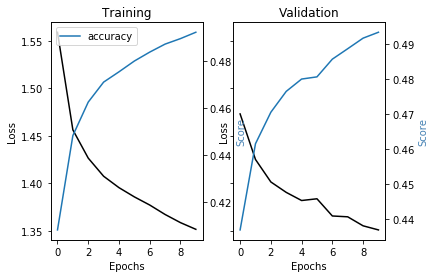

In [69]:
import matplotlib.pyplot as plt
metrics = [k for k in training.history.keys() if ("loss" not in k) and ("val" not in k)]
fig, ax = plt.subplots(nrows=1, ncols=2, sharey=True)
ax[0].set(title="Training")
ax11 = ax[0].twinx()
ax[0].plot(training.history['loss'], color='black')
ax[0].set_xlabel('Epochs')
ax[0].set_ylabel('Loss', color='black')
for metric in metrics:
    ax11.plot(training.history[metric], label=metric)
ax11.set_ylabel("Score", color='steelblue')
ax11.legend()
ax[1].set(title="Validation")
ax22 = ax[1].twinx()
ax[1].plot(training.history['val_loss'], color='black')
ax[1].set_xlabel('Epochs')
ax[1].set_ylabel('Loss', color='black')
for metric in metrics:
     ax22.plot(training.history['val_'+metric], label=metric)
ax22.set_ylabel("Score", color="steelblue")
plt.show()

In [1]:
import tensorflow as tf
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))

Num GPUs Available:  0


In [2]:
from tensorflow.python.client import device_lib 
print(device_lib.list_local_devices())

[name: "/device:CPU:0"
device_type: "CPU"
memory_limit: 268435456
locality {
}
incarnation: 5201899718935289353
xla_global_id: -1
]
